# Semirrecta y método de reflexión

Para $x>0$, la ecuación $u_{tt}-c^2u_{xx}=0$ se reduce al problema de Cauchy en la recta extendiendo los datos.

- Dirichlet homogénea, $u(0,t)=0$: extensión **impar** de $f$ y $g$.
- Neumann homogénea, $u_x(0,t)=0$: extensión **par** de $f$ y $g$.

La paridad conserva la condición de frontera durante la evolución. En Dirichlet el pulso reflejado cambia de signo; en Neumann conserva el signo. Para una solución clásica en la esquina se requieren las compatibilidades correspondientes, por ejemplo $f(0)=0$ en Dirichlet.

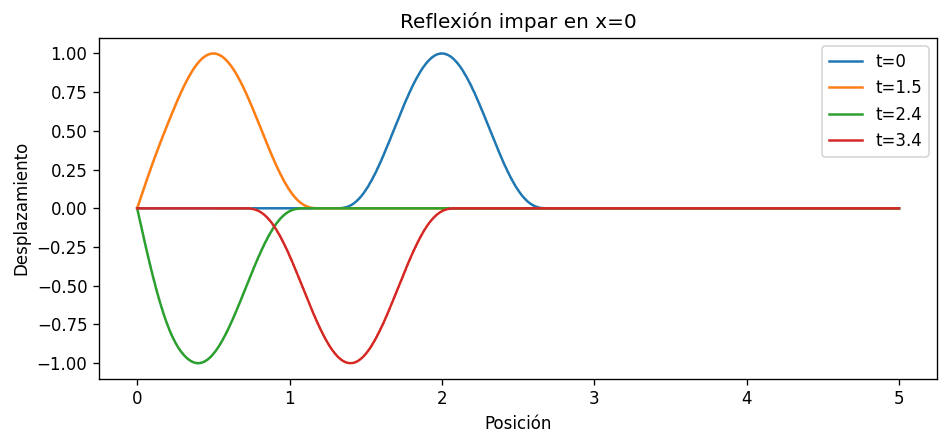

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,3.8))
ax.set(xlabel="Posición",ylabel="Desplazamiento")
x=np.linspace(0,5,400)
def pulso(z):
    return np.maximum(1-((z-2)/0.7)**2,0)**3
for t in [0,1.5,2.4,3.4]:
    ax.plot(x,pulso(x+t)-pulso(t-x),label=f"t={t:g}")
ax.set_title("Reflexión impar en x=0")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
from manim import *

class ReflexionEnFrontera(Scene):
    def construct(self):
        title = Text("Reflexión en x=0: Dirichlet cambia el signo", font_size=34).to_edge(UP)
        axes = Axes(x_range=[-5, 5, 1], y_range=[-1.5, 1.5, 0.5], x_length=10, y_length=4)
        wall = DashedLine(axes.c2p(0, -1.5), axes.c2p(0, 1.5), color=WHITE)
        incoming = axes.plot(lambda x: np.exp(-3*(x-2.5)**2), color=YELLOW)
        mirror = axes.plot(lambda x: -np.exp(-3*(x+2.5)**2), color=BLUE)
        labels = VGroup(
            Text("dato en x>0", font_size=25).next_to(axes, DOWN),
            Text("extensión impar en x<0", font_size=25).next_to(axes, DOWN)
        )
        self.play(FadeIn(title), Create(axes), Create(wall), Create(incoming), FadeIn(labels[0]))
        self.wait(4)
        self.play(Transform(labels[0], labels[1]), Create(mirror), run_time=3)
        group = VGroup(incoming, mirror)
        self.play(group.animate.shift(2.0*LEFT), run_time=6, rate_func=linear)
        conclusion = Text("en la pared los valores se cancelan", font_size=27).next_to(axes, DOWN)
        self.play(Transform(labels[0], conclusion))
        self.wait(3)

from IPython.display import Video, display

with tempconfig({"pixel_width": 2560, "pixel_height": 1440, "frame_rate": 120,
                 "write_to_movie": True, "format": "mp4", "preview": False}):
    escena = ReflexionEnFrontera()
    escena.render()
    pelicula = escena.renderer.file_writer.movie_file_path
display(Video(str(pelicula), embed=True))


## Ejercicios esenciales

1. Resuelva en $x>0$ el problema de Dirichlet homogéneo con $f(x)=xe^{-x}$ y $g=0$. Escriba la extensión de forma explícita y determine cuándo el pulso alcanza la frontera.
2. Para Neumann homogénea, derive la fórmula de representación usando extensiones pares y compruebe directamente que $u_x(0,t)=0$.

**Error típico.** Reflejar el perfil pero olvidar reflejar también la velocidad inicial.